<a href="https://colab.research.google.com/github/alameenShameer/Student_Depression_EDA_Preprocessing/blob/main/Student_Depression_EDA_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Importing Libraries

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder

#Loading data

In [63]:
df_students=pd.read_csv('/content/drive/MyDrive/ICT AI ML Files/dataset/Student_Depression_Dataset.csv')
df_students.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [64]:
df_students.shape

(4464, 13)

In [65]:
# df_students.describe()

In [66]:
df_students.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   object 
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   object 
 3   Relationship_status  4464 non-null   object 
 4   Marital_status       4464 non-null   object 
 5   Living_style         4464 non-null   object 
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   object 
 9   Health_condition     4464 non-null   object 
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   object 
 12  Depression           4464 non-null   object 
dtypes: float64(1), int64(3), object(9)
memory usage: 453.5+ KB


##Splitting the data into numerical and categorical


In [67]:
num_cols=df_students.select_dtypes(include='number').columns
cat_cols=df_students.select_dtypes(include='object').columns
print(num_cols)
print(cat_cols)

Index(['Age', 'Current_semester', 'CGPA', 'Cost_without_study'], dtype='object')
Index(['Gender', 'Family_background', 'Relationship_status', 'Marital_status',
       'Living_style', 'friend_circle', 'Health_condition', 'Home_division',
       'Depression'],
      dtype='object')


#Handling Numerical values



##Handling Missing Values

In [68]:
df_students[num_cols].isna().sum()

,0
Age,0
Current_semester,0
CGPA,0
Cost_without_study,0


##Handling Duplicate Values

In [69]:
df_students.duplicated().sum()

np.int64(0)

##Outliers Handling

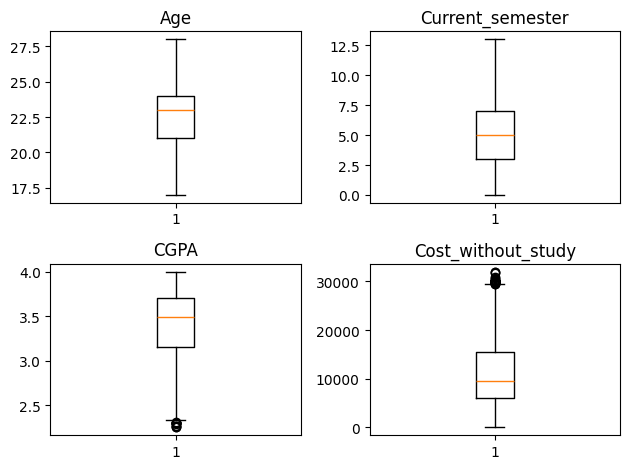

In [70]:
for i,col in enumerate(num_cols,1):
  plt.subplot(2,2,i)
  plt.boxplot(df_students[col])
  plt.title(col)
plt.tight_layout()
plt.show()

In [71]:
columns=['CGPA','Cost_without_study']
df_students['CGPA']=df_students['CGPA'].clip()
q1=df_students[columns].quantile(.25)
q3=df_students[columns].quantile(.75)

iqr=q3-q1

lower=q1-iqr*1.5
upper=q3+iqr*1.5

df_students[columns]=df_students[columns].clip(lower,upper,axis=1)

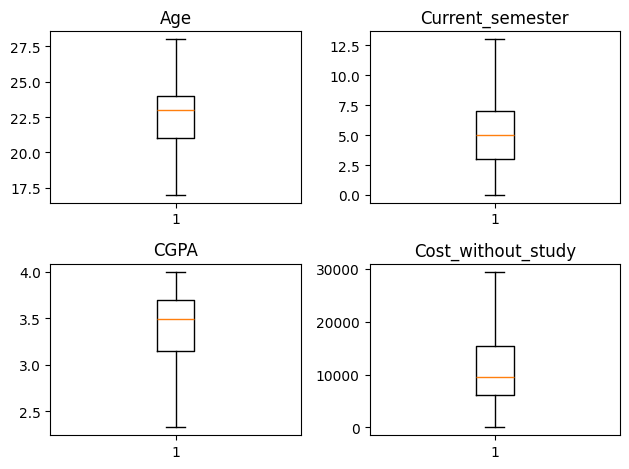

In [72]:
for i,col in enumerate(num_cols,1):
  plt.subplot(2,2,i)
  plt.boxplot(df_students[col])
  plt.title(col)
plt.tight_layout()
plt.show()

##Standardisation/Scaling


In [73]:
scaler = StandardScaler()
df_students[num_cols]=scaler.fit_transform(df_students[num_cols])
df_students.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,-0.306105,Middle class,Single,Unmarried,Bachelor,1.007991,0.044499,Yes,Critical,-0.169789,Chittagong,Yes
1,Male,-1.789232,Middle class,Single,Unmarried,Bachelor,-1.319225,0.745317,Yes,Abnormal,0.389028,Chittagong,Yes
2,Male,0.188270,Middle class,Single,Unmarried,Family,1.007991,-0.344844,No,Abnormal,0.635831,Dhaka,Yes
3,Male,-1.294857,Middle class,Complicated,Unmarried,Family,-1.319225,0.927010,No,Good,0.932146,Dhaka,No
4,Female,-0.800481,Middle class,Single,Unmarried,Family,-1.707095,1.524004,No,Abnormal,0.823462,Dhaka,Yes


#Handling Categorical values


##Handling Missing values

In [74]:
df_students[cat_cols].isna().sum()

,0
Gender,0
Family_background,0
Relationship_status,0
Marital_status,0
Living_style,0
friend_circle,0
Health_condition,0
Home_division,0
Depression,0


##Encoding

###Label Encoding

In [75]:
df_students['Depression'].unique()

array(['Yes', 'No'], dtype=object)

In [76]:
label_encoder = LabelEncoder()
df_students['Depression']=label_encoder.fit_transform(df_students['Depression'])
df_students.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,-0.306105,Middle class,Single,Unmarried,Bachelor,1.007991,0.044499,Yes,Critical,-0.169789,Chittagong,1
1,Male,-1.789232,Middle class,Single,Unmarried,Bachelor,-1.319225,0.745317,Yes,Abnormal,0.389028,Chittagong,1
2,Male,0.188270,Middle class,Single,Unmarried,Family,1.007991,-0.344844,No,Abnormal,0.635831,Dhaka,1
3,Male,-1.294857,Middle class,Complicated,Unmarried,Family,-1.319225,0.927010,No,Good,0.932146,Dhaka,0
4,Female,-0.800481,Middle class,Single,Unmarried,Family,-1.707095,1.524004,No,Abnormal,0.823462,Dhaka,1


In [77]:
df_students['Depression'].unique()

array([1, 0])

In [78]:
df_students['Health_condition'].unique()

array(['Critical', 'Abnormal', 'Good', 'Normal'], dtype=object)

###Ordinal Encoding

In [79]:
encoder_health=OrdinalEncoder(
  categories=[['Normal','Good','Abnormal','Critical']]
)

df_students['Health_condition']=encoder_health.fit_transform(df_students[['Health_condition']])

df_students.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,-0.306105,Middle class,Single,Unmarried,Bachelor,1.007991,0.044499,Yes,3.0,-0.169789,Chittagong,1
1,Male,-1.789232,Middle class,Single,Unmarried,Bachelor,-1.319225,0.745317,Yes,2.0,0.389028,Chittagong,1
2,Male,0.188270,Middle class,Single,Unmarried,Family,1.007991,-0.344844,No,2.0,0.635831,Dhaka,1
3,Male,-1.294857,Middle class,Complicated,Unmarried,Family,-1.319225,0.927010,No,1.0,0.932146,Dhaka,0
4,Female,-0.800481,Middle class,Single,Unmarried,Family,-1.707095,1.524004,No,2.0,0.823462,Dhaka,1


In [80]:
print(df_students['Family_background'].unique())
encoder_family=OrdinalEncoder(
    categories=[['Lower Middle class','Middle class','Rich class']]
)
df_students['Family_background']=encoder_family.fit_transform(df_students[['Family_background']])
df_students.head()

['Middle class' 'Lower Middle class' 'Rich class']


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,-0.306105,1.0,Single,Unmarried,Bachelor,1.007991,0.044499,Yes,3.0,-0.169789,Chittagong,1
1,Male,-1.789232,1.0,Single,Unmarried,Bachelor,-1.319225,0.745317,Yes,2.0,0.389028,Chittagong,1
2,Male,0.188270,1.0,Single,Unmarried,Family,1.007991,-0.344844,No,2.0,0.635831,Dhaka,1
3,Male,-1.294857,1.0,Complicated,Unmarried,Family,-1.319225,0.927010,No,1.0,0.932146,Dhaka,0
4,Female,-0.800481,1.0,Single,Unmarried,Family,-1.707095,1.524004,No,2.0,0.823462,Dhaka,1


##One Hot Encoding

In [81]:
encoder_gender=OneHotEncoder()
encoded_data=encoder_gender.fit_transform(df_students[['Gender']])

encoded_df=pd.DataFrame(
    encoded_data.toarray(),
    columns=encoder_gender.get_feature_names_out(['Gender']),
    index=df_students.index
)


df_students=pd.concat([df_students.drop(columns=['Gender'],axis=1), encoded_df],axis=1)

In [82]:
df_students.head()

,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression,Gender_Female,Gender_Male
0,-0.306105,1.0,Single,Unmarried,Bachelor,1.007991,0.044499,Yes,3.0,-0.169789,Chittagong,1,1.0,0.0
1,-1.789232,1.0,Single,Unmarried,Bachelor,-1.319225,0.745317,Yes,2.0,0.389028,Chittagong,1,0.0,1.0
2,0.188270,1.0,Single,Unmarried,Family,1.007991,-0.344844,No,2.0,0.635831,Dhaka,1,0.0,1.0
3,-1.294857,1.0,Complicated,Unmarried,Family,-1.319225,0.927010,No,1.0,0.932146,Dhaka,0,0.0,1.0
4,-0.800481,1.0,Single,Unmarried,Family,-1.707095,1.524004,No,2.0,0.823462,Dhaka,1,1.0,0.0


In [83]:
encoder_relationship=OneHotEncoder()
encoded_data=encoder_relationship.fit_transform(df_students[['Relationship_status']])
encoded_df=pd.DataFrame(
    encoded_data.toarray(),
    columns=encoder_relationship.get_feature_names_out(['Relationship_status']),
    index=df_students.index
)

df_students=pd.concat([df_students.drop(columns=['Relationship_status'],axis=1),encoded_df],axis=1)
df_students.head()

,Age,Family_background,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression,Gender_Female,Gender_Male,Relationship_status_Complicated,Relationship_status_In a Relationship,Relationship_status_Single
0,-0.306105,1.0,Unmarried,Bachelor,1.007991,0.044499,Yes,3.0,-0.169789,Chittagong,1,1.0,0.0,0.0,0.0,1.0
1,-1.789232,1.0,Unmarried,Bachelor,-1.319225,0.745317,Yes,2.0,0.389028,Chittagong,1,0.0,1.0,0.0,0.0,1.0
2,0.188270,1.0,Unmarried,Family,1.007991,-0.344844,No,2.0,0.635831,Dhaka,1,0.0,1.0,0.0,0.0,1.0
3,-1.294857,1.0,Unmarried,Family,-1.319225,0.927010,No,1.0,0.932146,Dhaka,0,0.0,1.0,1.0,0.0,0.0
4,-0.800481,1.0,Unmarried,Family,-1.707095,1.524004,No,2.0,0.823462,Dhaka,1,1.0,0.0,0.0,0.0,1.0


In [84]:
encoder_marital=OneHotEncoder()
encoded_data=encoder_marital.fit_transform(df_students[['Marital_status']])
encoded_df=pd.DataFrame(
    encoded_data.toarray(),
    columns=encoder_marital.get_feature_names_out(['Marital_status']),
    index=df_students.index
)

df_students=pd.concat([df_students.drop(columns=['Marital_status'],axis=1),encoded_df],axis=1)
df_students.head()

,Age,Family_background,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression,Gender_Female,Gender_Male,Relationship_status_Complicated,Relationship_status_In a Relationship,Relationship_status_Single,Marital_status_Married,Marital_status_Separated,Marital_status_Unmarried
0,-0.306105,1.0,Bachelor,1.007991,0.044499,Yes,3.0,-0.169789,Chittagong,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
1,-1.789232,1.0,Bachelor,-1.319225,0.745317,Yes,2.0,0.389028,Chittagong,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
2,0.188270,1.0,Family,1.007991,-0.344844,No,2.0,0.635831,Dhaka,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
3,-1.294857,1.0,Family,-1.319225,0.927010,No,1.0,0.932146,Dhaka,0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
4,-0.800481,1.0,Family,-1.707095,1.524004,No,2.0,0.823462,Dhaka,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0


In [85]:
encoder_living=OneHotEncoder()
encoded_data=encoder_living.fit_transform(df_students[['Living_style']])
encoded_df=pd.DataFrame(
    encoded_data.toarray(),
    columns=encoder_living.get_feature_names_out(['Living_style']),
    index=df_students.index
)

df_students=pd.concat([df_students.drop(columns=['Living_style'],axis=1),encoded_df],axis=1)
df_students.head()

,Age,Family_background,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression,Gender_Female,Gender_Male,Relationship_status_Complicated,Relationship_status_In a Relationship,Relationship_status_Single,Marital_status_Married,Marital_status_Separated,Marital_status_Unmarried,Living_style_Bachelor,Living_style_Family
0,-0.306105,1.0,1.007991,0.044499,Yes,3.0,-0.169789,Chittagong,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
1,-1.789232,1.0,-1.319225,0.745317,Yes,2.0,0.389028,Chittagong,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
2,0.188270,1.0,1.007991,-0.344844,No,2.0,0.635831,Dhaka,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
3,-1.294857,1.0,-1.319225,0.927010,No,1.0,0.932146,Dhaka,0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
4,-0.800481,1.0,-1.707095,1.524004,No,2.0,0.823462,Dhaka,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0


In [86]:
encoder_home=OneHotEncoder()
encoded_data=encoder_home.fit_transform(df_students[['Home_division']])
encoded_df=pd.DataFrame(
    encoded_data.toarray(),
    columns=encoder_home.get_feature_names_out(['Home_division']),
    index=df_students.index
)

df_students=pd.concat([df_students.drop(columns=['Home_division'],axis=1),encoded_df],axis=1)
df_students.head()

,Age,Family_background,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Depression,Gender_Female,Gender_Male,...,Living_style_Bachelor,Living_style_Family,Home_division_Barisal,Home_division_Chittagong,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet
0,-0.306105,1.0,1.007991,0.044499,Yes,3.0,-0.169789,1,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,-1.789232,1.0,-1.319225,0.745317,Yes,2.0,0.389028,1,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.188270,1.0,1.007991,-0.344844,No,2.0,0.635831,1,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,-1.294857,1.0,-1.319225,0.927010,No,1.0,0.932146,0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,-0.800481,1.0,-1.707095,1.524004,No,2.0,0.823462,1,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [87]:
encoder_friend=OneHotEncoder()
encoded_data=encoder_friend.fit_transform(df_students[['friend_circle']])
encoded_df=pd.DataFrame(
    encoded_data.toarray(),
    columns=encoder_friend.get_feature_names_out(['friend_circle']),
    index=df_students.index
)

df_students=pd.concat([df_students.drop(columns=['friend_circle'],axis=1),encoded_df],axis=1)
df_students.head()

,Age,Family_background,Current_semester,CGPA,Health_condition,Cost_without_study,Depression,Gender_Female,Gender_Male,Relationship_status_Complicated,...,Home_division_Barisal,Home_division_Chittagong,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet,friend_circle_No,friend_circle_Yes
0,-0.306105,1.0,1.007991,0.044499,3.0,-0.169789,1,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,-1.789232,1.0,-1.319225,0.745317,2.0,0.389028,1,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.188270,1.0,1.007991,-0.344844,2.0,0.635831,1,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,-1.294857,1.0,-1.319225,0.927010,1.0,0.932146,0,0.0,1.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,-0.800481,1.0,-1.707095,1.524004,2.0,0.823462,1,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
